# Project 1 of 3: Exploratory Data Analysis (EDA) for Machine Learning
**Studi Kasus:** Analisis Indikator Sosio-Ekonomi 35 Kabupaten/Kota di Jawa Tengah (Data BPS 2025)

Kurikulum **Course 1 — Exploratory Data Analysis for Machine Learning**:
1. **Step 1 — Data Retrieval & Schema Inspection**
2. **Step 2 — Data Cleaning & Outlier Detection (Metode IQR)**
3. **Step 3 — Skewness Analysis & Transformasi Logaritma $\ln(\text{PDRB})$**
4. **Step 4 — Feature Engineering & Categorical Encoding**
5. **Step 5 — Feature Scaling (`StandardScaler` vs `MinMaxScaler`)**
6. **Step 6 — Uji Hipotesis Statistik (*Welch's T-Test*) & Matriks Korelasi**
7. **Step 7 — Visualisasi Dashboard 4-Panel EDA**

In [1]:
import os
import warnings
from math import erf, sqrt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
np.random.seed(42)

def locate_dataset() -> str:
    cwd = os.getcwd()
    for p in [
        os.path.join(cwd, "bps_jawa_tengah_2025.csv"),
        os.path.join(cwd, "..", "bps_jawa_tengah_2025.csv"),
        os.path.join(cwd, "data", "bps_jawa_tengah_2025.csv"),
        "bps_jawa_tengah_2025.csv",
    ]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError("Pastikan 'bps_jawa_tengah_2025.csv' ada di folder proyek.")

df = pd.read_csv(locate_dataset())
print(f"Dimensi Dataset: {df.shape[0]} Kabupaten/Kota x {df.shape[1]} Kolom")
df.head()

Dimensi Dataset: 35 Kabupaten/Kota x 12 Kolom


,kode_bps,nama_wilayah,tipe_wilayah,ipm_2025,persentase_penduduk_miskin_2025,pdrb_adhb_2025_triliun_rp,kontribusi_pdrb_jateng_persen,peringkat_pdrb_2025,hls_laki_laki_2025,hls_perempuan_2025,uhh_laki_laki_2025,uhh_perempuan_2025
0,3301,Kabupaten Cilacap,Kabupaten,73.45,9.41,142.71,7.35,2,13.12,12.70,73.44,78.14
1,3302,Kabupaten Banyumas,Kabupaten,75.44,11.15,79.80,4.11,4,13.46,13.64,72.75,77.46
2,3303,Kabupaten Purbalingga,Kabupaten,71.71,12.55,36.07,1.86,23,12.26,12.10,72.57,77.07
3,3304,Kabupaten Banjarnegara,Kabupaten,70.61,13.28,31.35,1.61,27,12.03,12.04,73.19,76.82
4,3305,Kabupaten Kebumen,Kabupaten,73.17,13.58,41.52,2.14,19,13.42,13.59,73.66,77.55


### Step 2: Pemeriksaan Kualitas Data & Deteksi Outlier (IQR)

In [2]:
print(f"Missing Values : {int(df.isnull().sum().sum())} sel kosong")
print(f"Data Duplikat  : {int(df.duplicated().sum())} baris duplikat")

num_cols = [
    "ipm_2025",
    "persentase_penduduk_miskin_2025",
    "pdrb_adhb_2025_triliun_rp",
    "hls_laki_laki_2025",
    "hls_perempuan_2025",
    "uhh_laki_laki_2025",
    "uhh_perempuan_2025",
]

iqr_summary = []
for col in num_cols:
    q1, med, q3 = df[col].quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    iqr_summary.append({"Variabel": col, "Q1": round(q1, 2), "Median": round(med, 2), "Q3": round(q3, 2), "Batas Atas IQR": round(high, 2), "Outlier": n_out})

pd.DataFrame(iqr_summary)

Missing Values : 0 sel kosong
Data Duplikat  : 0 baris duplikat


,Variabel,Q1,Median,Q3,Batas Atas IQR,Outlier
0,ipm_2025,72.61,74.98,77.85,85.70,2
1,persentase_penduduk_miskin_2025,7.05,8.71,11.07,17.10,0
2,pdrb_adhb_2025_triliun_rp,32.02,42.82,61.03,104.55,3
3,hls_laki_laki_2025,12.64,13.11,13.43,14.60,4
4,hls_perempuan_2025,12.74,13.22,13.63,14.96,3
5,uhh_laki_laki_2025,73.19,73.70,75.07,77.88,0
6,uhh_perempuan_2025,77.14,78.03,78.89,81.51,0


### Step 3 & 4: Skewness Transformation & Feature Engineering

In [3]:
def compute_skewness(series: pd.Series) -> float:
    x = series.dropna().values.astype(float)
    std = np.std(x, ddof=1)
    return float(np.mean(((x - np.mean(x)) / std) ** 3)) if std > 0 else 0.0

skew_raw = compute_skewness(df["pdrb_adhb_2025_triliun_rp"])
df["sqrt_pdrb"] = np.sqrt(df["pdrb_adhb_2025_triliun_rp"])
df["log_pdrb"] = np.log(df["pdrb_adhb_2025_triliun_rp"])
skew_log = compute_skewness(df["log_pdrb"])

df["hls_rata_rata"] = ((df["hls_laki_laki_2025"] + df["hls_perempuan_2025"]) / 2.0).round(3)
df["uhh_rata_rata"] = ((df["uhh_laki_laki_2025"] + df["uhh_perempuan_2025"]) / 2.0).round(3)
df["gap_hls_gender"] = (df["hls_perempuan_2025"] - df["hls_laki_laki_2025"]).round(3)
df["gap_uhh_gender"] = (df["uhh_perempuan_2025"] - df["uhh_laki_laki_2025"]).round(3)
df["rasio_pendidikan_kesehatan"] = (df["hls_rata_rata"] / df["uhh_rata_rata"]).round(4)
df["is_kota"] = (df["tipe_wilayah"] == "Kota").astype(int)

print(f"Skewness PDRB Raw: {skew_raw:+.4f} -> Skewness ln(PDRB): {skew_log:+.4f}")
df[["nama_wilayah", "tipe_wilayah", "ipm_2025", "hls_rata_rata", "uhh_rata_rata", "log_pdrb", "is_kota"]].head()

Skewness PDRB Raw: +3.2432 -> Skewness ln(PDRB): +0.6491


,nama_wilayah,tipe_wilayah,ipm_2025,hls_rata_rata,uhh_rata_rata,log_pdrb,is_kota
0,Kabupaten Cilacap,Kabupaten,73.45,12.910,75.790,4.960815,0
1,Kabupaten Banyumas,Kabupaten,75.44,13.550,75.105,4.379524,0
2,Kabupaten Purbalingga,Kabupaten,71.71,12.180,74.820,3.585461,0
3,Kabupaten Banjarnegara,Kabupaten,70.61,12.035,75.005,3.445214,0
4,Kabupaten Kebumen,Kabupaten,73.17,13.505,75.605,3.726175,0


### Step 5 & 6: Uji Hipotesis Welch's T-Test (Kota vs Kabupaten) & Korelasi Pearson

In [4]:
def welch_t_test(g1, g2):
    n1, n2 = len(g1), len(g2)
    m1, m2 = np.mean(g1), np.mean(g2)
    v1, v2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    se = np.sqrt(v1 / n1 + v2 / n2)
    t_stat = (m1 - m2) / se
    p_val = 2.0 * (1.0 - 0.5 * (1.0 + erf(abs(t_stat) / sqrt(2.0))))
    return float(t_stat), float(p_val)

t_ipm, p_ipm = welch_t_test(df[df["is_kota"] == 1]["ipm_2025"].values, df[df["is_kota"] == 0]["ipm_2025"].values)
t_pov, p_pov = welch_t_test(df[df["is_kota"] == 1]["persentase_penduduk_miskin_2025"].values, df[df["is_kota"] == 0]["persentase_penduduk_miskin_2025"].values)

print(f"Welch's T-Test IPM (Kota vs Kabupaten)        : t = {t_ipm:+.4f}, p = {p_ipm:.6f}")
print(f"Welch's T-Test Kemiskinan (Kota vs Kabupaten) : t = {t_pov:+.4f}, p = {p_pov:.6f}")

corr_cols = ["ipm_2025", "persentase_penduduk_miskin_2025", "hls_rata_rata", "uhh_rata_rata", "log_pdrb", "gap_hls_gender", "is_kota"]
df[corr_cols].corr().round(4)

Welch's T-Test IPM (Kota vs Kabupaten)        : t = +5.1060, p = 0.000000
Welch's T-Test Kemiskinan (Kota vs Kabupaten) : t = -5.1499, p = 0.000000


,ipm_2025,persentase_penduduk_miskin_2025,hls_rata_rata,uhh_rata_rata,log_pdrb,gap_hls_gender,is_kota
ipm_2025,1.0000,-0.6752,0.9344,0.8375,0.1409,0.2224,0.7536
persentase_penduduk_miskin_2025,-0.6752,1.0000,-0.6229,-0.5583,-0.1044,-0.2241,-0.5543
hls_rata_rata,0.9344,-0.6229,1.0000,0.7847,0.2211,0.0619,0.6688
uhh_rata_rata,0.8375,-0.5583,0.7847,1.0000,0.2425,0.2285,0.4036
log_pdrb,0.1409,-0.1044,0.2211,0.2425,1.0000,-0.1139,-0.1972
gap_hls_gender,0.2224,-0.2241,0.0619,0.2285,-0.1139,1.0000,0.0409
is_kota,0.7536,-0.5543,0.6688,0.4036,-0.1972,0.0409,1.0000


### Step 7: Visualisasi Dashboard 4-Panel EDA

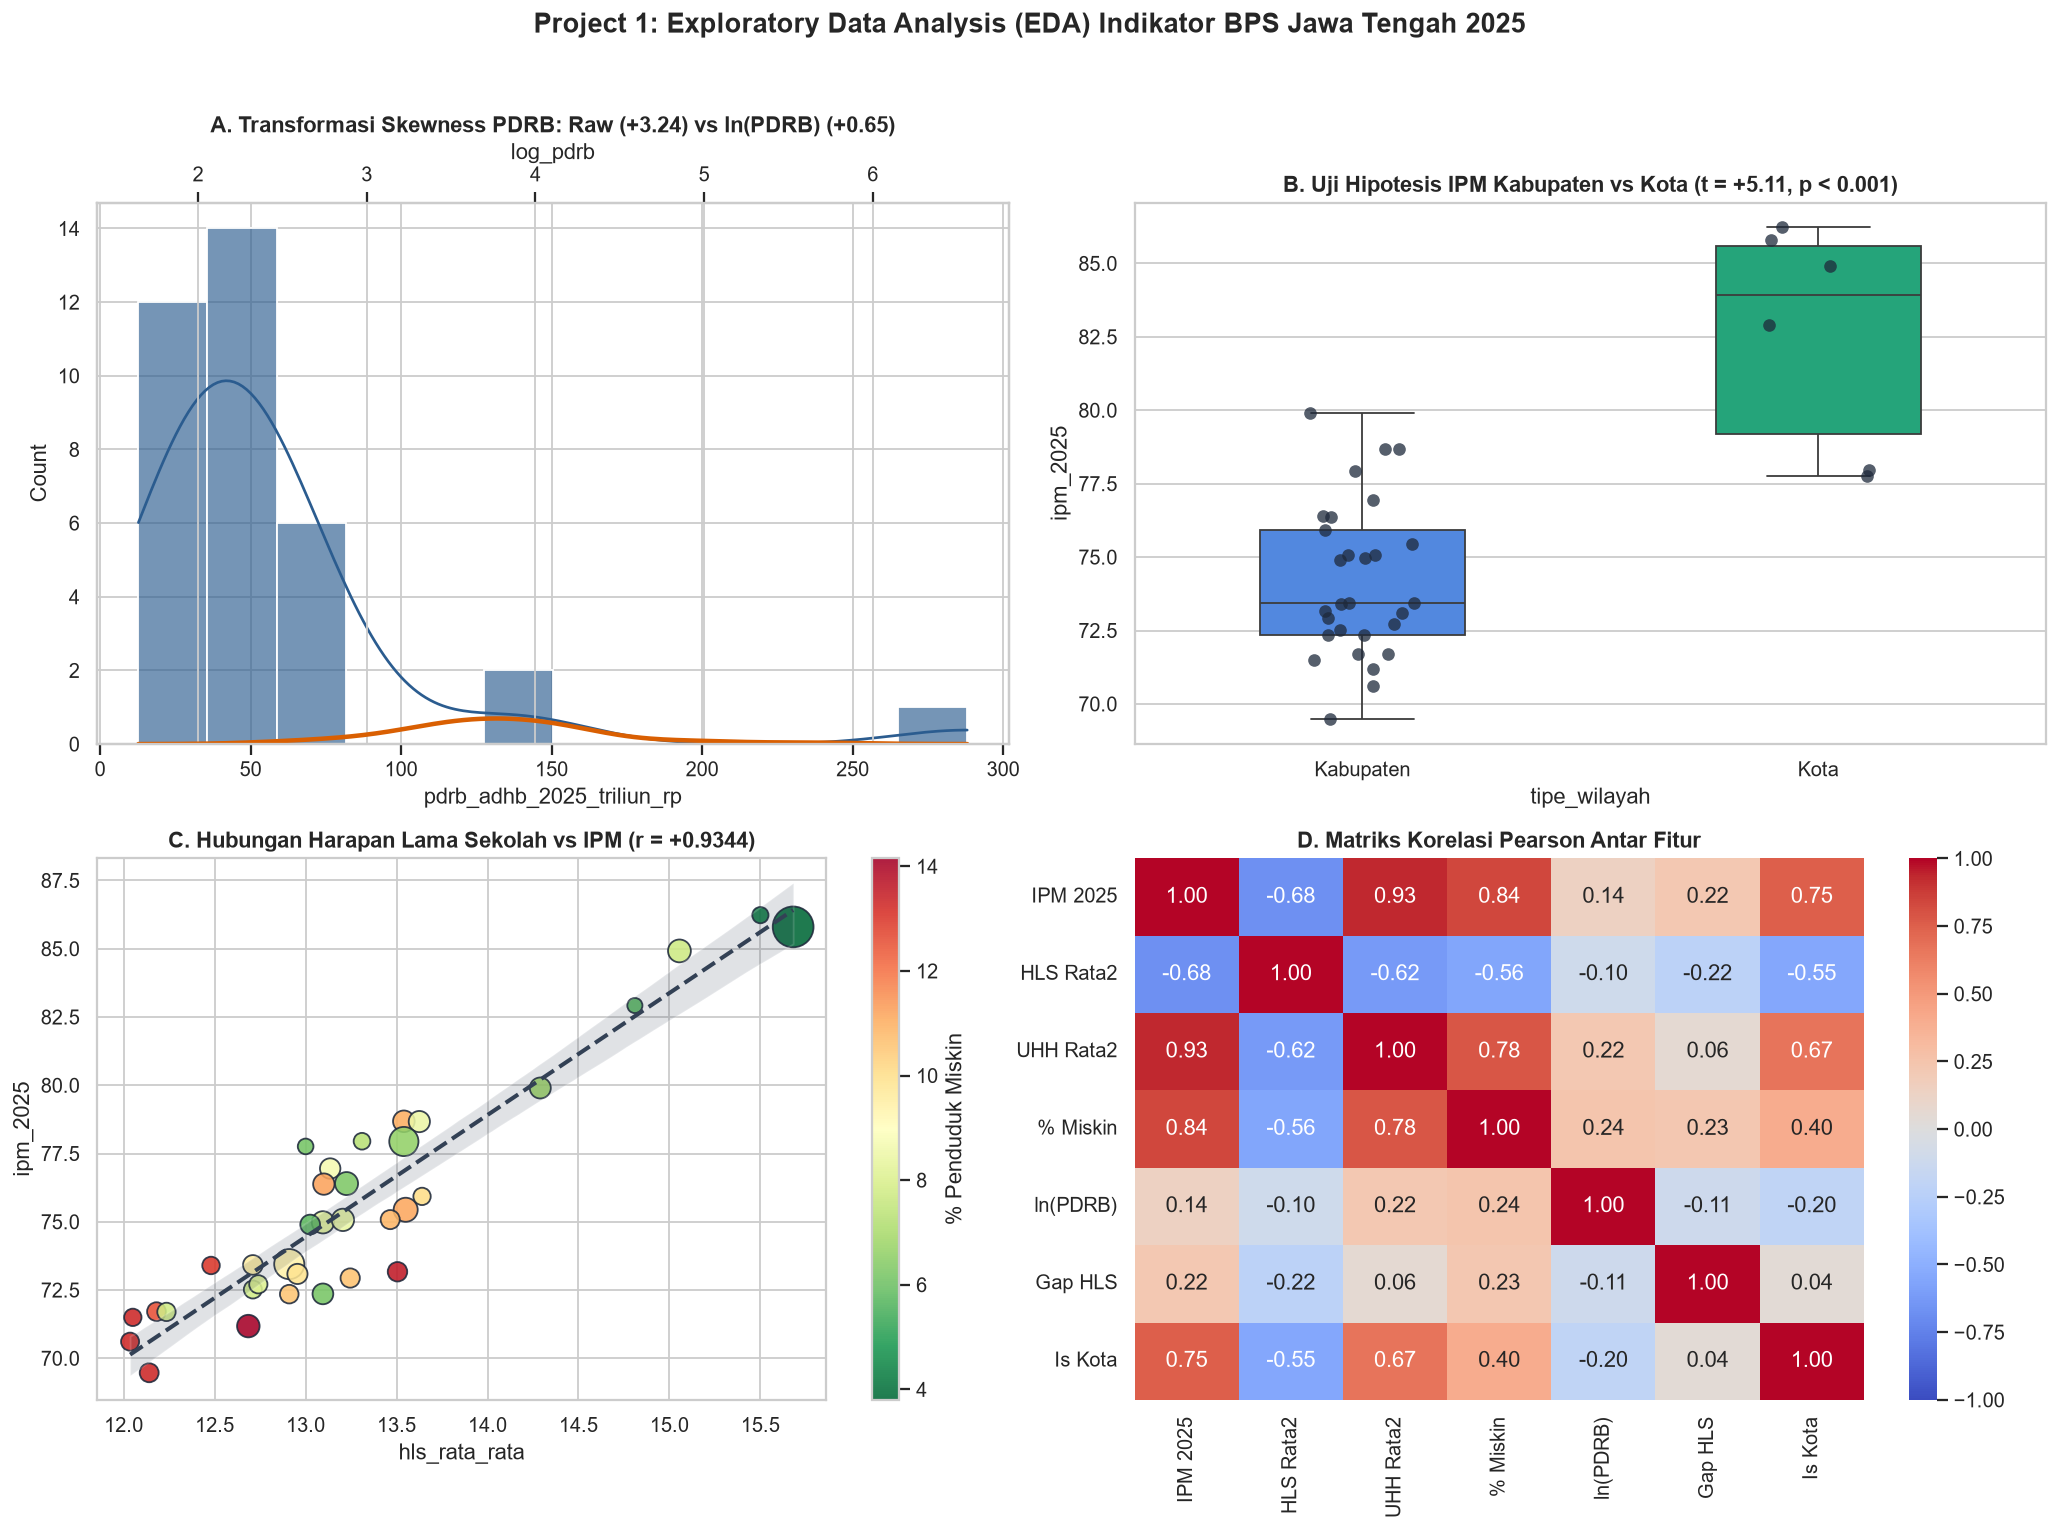

In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=130)
fig.suptitle("Project 1: Exploratory Data Analysis (EDA) Indikator BPS Jawa Tengah 2025", fontsize=15, fontweight="bold", y=0.98)

ax1 = axes[0, 0]
sns.histplot(df["pdrb_adhb_2025_triliun_rp"], kde=True, color="#2b5c8f", bins=12, ax=ax1, alpha=0.65)
ax1_t = ax1.twiny()
sns.kdeplot(df["log_pdrb"], color="#d95f02", linewidth=2.5, ax=ax1_t)
ax1.set_title(f"A. Transformasi Skewness PDRB: Raw ({skew_raw:+.2f}) vs ln(PDRB) ({skew_log:+.2f})", fontweight="bold")

ax2 = axes[0, 1]
sns.boxplot(data=df, x="tipe_wilayah", y="ipm_2025", palette={"Kabupaten": "#3b82f6", "Kota": "#10b981"}, width=0.45, ax=ax2)
sns.stripplot(data=df, x="tipe_wilayah", y="ipm_2025", color="#1e293b", size=7, jitter=0.12, alpha=0.75, ax=ax2)
ax2.set_title(f"B. Uji Hipotesis IPM Kabupaten vs Kota (t = {t_ipm:+.2f}, p < 0.001)", fontweight="bold")

ax3 = axes[1, 0]
sc = ax3.scatter(df["hls_rata_rata"], df["ipm_2025"], c=df["persentase_penduduk_miskin_2025"], s=df["pdrb_adhb_2025_triliun_rp"]*1.6+50, cmap="RdYlGn_r", alpha=0.88, edgecolors="#1e293b")
sns.regplot(data=df, x="hls_rata_rata", y="ipm_2025", scatter=False, ax=ax3, color="#334155", line_kws={"linestyle": "--"})
plt.colorbar(sc, ax=ax3, label="% Penduduk Miskin")
ax3.set_title("C. Hubungan Harapan Lama Sekolah vs IPM (r = +0.9344)", fontweight="bold")

ax4 = axes[1, 1]
labels_s = ["IPM 2025", "HLS Rata2", "UHH Rata2", "% Miskin", "ln(PDRB)", "Gap HLS", "Is Kota"]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, xticklabels=labels_s, yticklabels=labels_s, ax=ax4)
ax4.set_title("D. Matriks Korelasi Pearson Antar Fitur", fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()